<a href="https://colab.research.google.com/github/husthorng/fourier/blob/main/FFT1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
vibration_signal

array([ 0.07378903,  0.21875756,  0.3715841 ,  1.49034087,  0.72139456,
        1.40362082,  1.52594637,  1.18985022,  1.26834902,  1.07607304,
        1.17541517,  0.50168973,  0.28566311,  0.55854403,  0.03114997,
        0.35453494, -0.00546943,  0.40337901,  1.42973745,  0.54488919,
        1.18626574,  1.87818594,  1.80013262,  1.88253394,  1.43957518,
        2.15556067,  2.17131137,  2.42390242,  1.33485836,  1.527809  ,
        1.98769931,  0.99795619,  0.92108268,  0.65742393, -0.15176835,
        0.19277271,  0.23262899,  0.79311732,  0.78539019,  0.88387863,
        1.36757629,  0.9155851 ,  0.99732949,  1.24044048,  1.0634642 ,
        1.30770585,  0.65624365,  1.5375772 ,  0.91276836,  0.53982688,
        0.52802461, -0.14481121, -0.9053386 , -0.60491105, -0.65559882,
       -0.68456872, -1.22043261, -1.77281531, -1.42284743, -1.07952013,
       -1.14326779, -0.23317786, -0.91914654, -0.89969444, -0.21087012,
       -0.69986837, -0.62184569, -1.2561631 , -0.61023456, -0.98

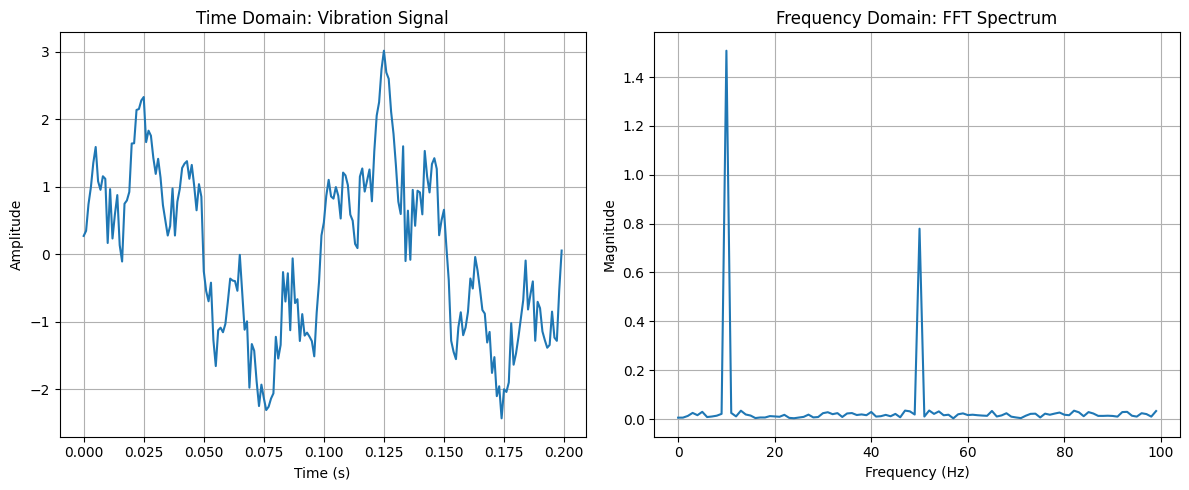

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. 建立模擬震動波形
sampling_rate = 1000  # 採樣率 (Hz) - 每秒採集 1000 個點
duration = 1.0        # 信號持續時間 (秒)
t = np.linspace(0, duration, int(sampling_rate * duration), endpoint=False)
#https://www.google.com/search?q=np.linspace+%E7%94%A8%E6%B3%95&oq=np.linspace&gs_lcrp=EgZjaHJvbWUqBwgBEAAYgAQyBggAEEUYOTIHCAEQABiABDIHCAIQABiABDIHCAMQABiABDIGCAQQABgeMgYIBRAAGB4yBggGEAAYHjIGCAcQABgeMgYICBAAGB4yBggJEAAYHtIBCTI3MjhqMGoxNagCCLACAQ&sourceid=chrome&ie=UTF-8

# 模擬震動信號：包含 10 Hz (振幅 1.5) 與 50 Hz (振幅 0.8) 加上少量雜訊
frequency1, amplitude1 = 10, 1.5
frequency2, amplitude2 = 50, 0.8
noise = np.random.normal(0, 0.3, len(t))

vibration_signal = amplitude1 * np.sin(2 * np.pi * frequency1 * t) + \
                   amplitude2 * np.sin(2 * np.pi * frequency2 * t) + noise
#vibration_signal = amplitude1 * np.sin(2 * np.pi * frequency1 * t)

#vibration_signal = 1.5*np.sin(2 * np.pi * 10 * t)+1.1*np.sin(2 * np.pi * 20 * t)

# 2. 進行快速傅立葉轉換 (FFT)
n = len(vibration_signal)
fft_result = np.fft.fft(vibration_signal)
frequencies = np.fft.fftfreq(n, d=1/sampling_rate)

# 取正頻率部分與單邊頻譜振幅校正
positive_freq_mask = frequencies >= 0
freqs_single = frequencies[positive_freq_mask]
fft_magnitude = np.abs(fft_result[positive_freq_mask]) * (2.0 / n)

# 3. 繪製時域與頻域對比圖
plt.figure(figsize=(12, 5))

# 時域圖 (Time Domain)
plt.subplot(1, 2, 1)
plt.plot(t[:200], vibration_signal[:200]) # 僅顯示前 0.2 秒以利觀看
plt.title("Time Domain: Vibration Signal")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.grid(True)

# 頻域圖 (Frequency Domain)
plt.subplot(1, 2, 2)
plt.plot(freqs_single[:100], fft_magnitude[:100]) # 顯示 0-100 Hz 範圍
plt.title("Frequency Domain: FFT Spectrum")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
# 2. 將時間與震動信號存成 CSV 檔
df = pd.DataFrame({
    'Time_s': t,
    'Vibration_Signal': vibration_signal
})
df.to_csv('/content/sample_data/vibration_signal.csv', index=False)
df.to_csv('/content/drive/MyDrive/FFT/vibration_signal.csv', index=False)

In [ ]:
/content/sample_data/mnist_test.csv

https://gemini.google.com/app/bf585b2a9aa80c0b

In [ ]:

import numpy as np
import pandas as pd

# 1. 讀取與 ESP32 相同的 CSV 檔案
df = pd.read_csv('/content/drive/MyDrive/FFT/vibration_signal.csv')
signal = df.iloc[:, -1].dropna().values

# 2. 參數必須與 ESP32 完全一致
SAMPLES = 1024
SAMPLING_FREQUENCY = 1000.0

# 擷取前 1024 筆 (若不足則補 0，與 ESP32 邏輯一致)
if len(signal) >= SAMPLES:
    x = signal[:SAMPLES].astype(np.float64)
else:
    x = np.pad(signal, (0, SAMPLES - len(signal)), 'constant').astype(np.float64)

# 3. 對應 ESP32 的 FFT.dcRemoval()
x = x - np.mean(x)

# 4. 對應 ESP32 的 FFT.windowing(FFTWindow::Hamming, FFTDirection::Forward)
window = np.hamming(SAMPLES)
x_windowed = x * window

# 5. 對應 ESP32 的 FFT.compute() + FFT.complexToMagnitude()
fft_complex = np.fft.fft(x_windowed)
magnitudes = np.abs(fft_complex[:SAMPLES // 2])
freqs = np.fft.fftfreq(SAMPLES, d=1.0/SAMPLING_FREQUENCY)[:SAMPLES // 2]

# 6. 印出結果與 ESP32 序列埠監控視窗比對
peak_idx = np.argmax(magnitudes[1:]) + 1  # 排除 0 Hz
print(f"離散網格主頻率: {freqs[peak_idx]:.2f} Hz (振幅: {magnitudes[peak_idx]:.4f})")

print("\n頻率(Hz)\t振幅(Magnitude)")
for i in range(1, SAMPLES // 2):
    if magnitudes[i] > 1.0:
        print(f"{freqs[i]:.2f} Hz\t\t{magnitudes[i]:.4f}")

離散網格主頻率: 9.77 Hz (振幅: 397.4234)

頻率(Hz)	振幅(Magnitude)
1.95 Hz		3.5589
2.93 Hz		6.5787
3.91 Hz		7.2903
4.88 Hz		7.6887
5.86 Hz		6.1279
6.84 Hz		2.2361
7.81 Hz		3.2550
8.79 Hz		106.8995
9.77 Hz		397.4234
10.74 Hz		256.5018
11.72 Hz		8.4061
12.70 Hz		10.3978
13.67 Hz		10.5670
14.65 Hz		6.0721
15.62 Hz		2.3847
16.60 Hz		1.5484
18.55 Hz		1.5386
19.53 Hz		2.7602
20.51 Hz		1.5887
21.48 Hz		1.9236
22.46 Hz		3.0565
25.39 Hz		3.0372
26.37 Hz		3.9731
27.34 Hz		4.8271
29.30 Hz		5.6537
30.27 Hz		10.2246
31.25 Hz		11.4169
32.23 Hz		9.5589
33.20 Hz		6.2333
34.18 Hz		3.8682
35.16 Hz		8.5809
36.13 Hz		6.7912
38.09 Hz		5.4076
39.06 Hz		4.8319
40.04 Hz		6.4654
41.02 Hz		2.9678
41.99 Hz		2.5593
42.97 Hz		5.3891
43.95 Hz		4.2416
44.92 Hz		5.6068
45.90 Hz		2.3291
46.88 Hz		13.1475
47.85 Hz		12.3578
48.83 Hz		60.9364
49.80 Hz		210.3211
50.78 Hz		131.7681
51.76 Hz		15.7695
52.73 Hz		14.1194
53.71 Hz		11.3100
54.69 Hz		11.2987
55.66 Hz		5.8030
56.64 Hz		3.7171
57.62 Hz		6.4446
58.59 Hz		9.1366
59.57 Hz		5.6809